In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
sys.path.append('..')
from SpikeGLX_Datafile_Tools.Python.DemoReadSGLXData.readSGLX import readMeta
from pathlib import Path
from tqdm import trange
import csv
import scipy.io
import scipy.stats
from scipy.signal import find_peaks

from Loading_functions import *
from Waveforms_functions import *

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager

# Manually create a font property using the full path
arial_font = font_manager.FontProperties(fname='/bucket/ReiterU/common/fonts/arial.ttf')

# Set default font family to use this font
mpl.rcParams['font.family'] = arial_font.get_name()

# Set other style settings
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})
mpl.rcParams['font.family'] = arial_font.get_name()


In [5]:
with open('WAVEFORM_EXP_NAMES.txt', 'r') as f:
    EXP_NAMES = [line.strip() for line in f if line.strip()]

In [6]:
gen_path='/bucket/ReiterU/electrophysiology/squidOL/'

In [8]:
ALL_SNRs = []
ALL_WAVEFORMs = []
ALL_FULL_WAVEFORMS = []
ALL_PRs = []
ALL_ISIs = []
ALL_AMPs = []
ALL_REAL_CHANNELS = []
dataset_ids = []
ALL_G_CHANNELS = []

for data_index in range(len(EXP_NAMES)):
    metric_path = gen_path + EXP_NAMES[data_index] + '/UNIT_METRICS'
    
    # Check if the UNIT_METRICS folder exists
    if os.path.exists(metric_path):
        # Find all probe folders (those starting with "probe")
        probe_folders = [f for f in os.listdir(metric_path) if f.startswith('probe')]
        
        for probe_folder in probe_folders:
            probe_num = probe_folder.replace('probe', '')
            dataset_ids.append(EXP_NAMES[data_index] + '/' + probe_folder)
            
            probe_path = metric_path + '/' + probe_folder + '/UNIT_METRICS'
            
            g_chans_path = gen_path + EXP_NAMES[data_index]
            for i in os.listdir(g_chans_path):
                if 'rec01' in i:
                    g_chans_path = g_chans_path + '/' + i + '/post_processed/' + probe_folder
            g_chans = np.load(g_chans_path + '/g_channels.npy')
            
            # Load SNRs, waveforms, big waveforms, ISIs, and amps
            snrs = np.load(probe_path + '/SNRs.npy', allow_pickle=True)
            waveforms = np.load(probe_path + '/peak_waveforms.npy', allow_pickle=True)
            big_waveforms = np.load(probe_path + '/waveforms.npy', allow_pickle=True)
            isis = np.load(probe_path + '/isi_viols.npy', allow_pickle=True)
            amps = np.load(probe_path + '/amps.npy', allow_pickle=True)
            
            # Check if 'presence_ratios.npy' exists or if 'presence_ratios_5s.npy' exists
            prs_file = probe_path + '/presence_ratios.npy'
            if not os.path.exists(prs_file):
                prs_file = probe_path + '/presence_ratios_5s.npy'
            
            prs = np.load(prs_file, allow_pickle=True)
            
            # Check if 'real_channels.npy' exists, and load it if so
            real_channels_file = probe_path + '/real_channels.npy'
            if os.path.exists(real_channels_file):
                real_channels = np.load(real_channels_file, allow_pickle=True)
            else:
                real_channels = np.array([])  # Append empty array if the file doesn't exist
            
            # Append all data to the lists
            ALL_SNRs.append(snrs)
            ALL_WAVEFORMs.append(waveforms)
            ALL_PRs.append(prs)
            ALL_ISIs.append(isis)
            ALL_AMPs.append(amps)
            ALL_FULL_WAVEFORMS.append(big_waveforms)
            ALL_REAL_CHANNELS.append(real_channels)
            ALL_G_CHANNELS.append(g_chans)
    
    else:
        print(EXP_NAMES[data_index])
        # If the UNIT_METRICS folder doesn't exist, append empty vectors
        ALL_SNRs.append(np.array([]))
        ALL_WAVEFORMs.append(np.array([]))
        ALL_FULL_WAVEFORMS.append(np.array([]))
        ALL_PRs.append(np.array([]))
        ALL_ISIs.append(np.array([]))
        ALL_AMPs.append(np.array([]))
        ALL_REAL_CHANNELS.append(np.array([]))





In [9]:
ALL_SNRs=np.asarray(ALL_SNRs,dtype='object')
ALL_WAVEFORMs=np.asarray(ALL_WAVEFORMs,dtype='object')
ALL_PRs=np.asarray(ALL_PRs,dtype='object')
ALL_ISIs=np.asarray(ALL_ISIs,dtype='object')
ALL_AMPs=np.asarray(ALL_AMPs,dtype='object')



In [52]:
SNRs=np.concatenate(ALL_SNRs)
SNRs=SNRs[np.isfinite(SNRs)]
#SNRs[SNRs<0.5]=np.nan # In case there are noise units
bin_size=0.6
bins=np.arange(0,np.nanmax(SNRs)+5*bin_size,bin_size)
snr_hist,_=np.histogram(SNRs,bins=bins)

2128


In [12]:
cm = 1/2.54

In [13]:
save_path='/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/UNIT_QUALITY_PLOTS/'

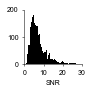

In [53]:
cm = 1 / 2.54  # cm to inches

fig = plt.figure(figsize=(2.8 * cm, 2.8 * cm))
ax = plt.gca()

ax.bar(bins[:-1], snr_hist, color='black', width=np.diff(bins)[0])

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlim([0, 30])
ax.set_ylim([0, np.max(snr_hist) * 1.1])


ax.set_xticks([0, 10,  20,  30])
ax.set_xticklabels([0, 10,  20,  30], fontproperties=arial_font,fontsize=7)
ax.set_yticks([0,100,200])
ax.set_yticklabels(ax.get_yticks(), fontproperties=arial_font,fontsize=7)

ax.set_xlabel('SNR', fontproperties=arial_font,fontsize=7)

# Save and show
plt.tight_layout(pad=0.05)
plt.savefig(save_path + '/SNRs.svg', format='svg', dpi=600)
plt.show()


In [45]:
PRs=np.concatenate(ALL_PRs)
PRs=PRs[np.isfinite(PRs)]
bin_size=0.02
bins=np.arange(0,1+bin_size,bin_size)
pr_hist,_=np.histogram(PRs,bins=bins)

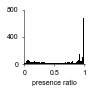

In [51]:
plt.figure(figsize=(2.8 * cm, 2.8 * cm))
ax = plt.gca()

plt.bar(bins[:-1] + bin_size / 2, pr_hist, color='black', width=bin_size)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlim([0, 1 + bin_size / 2])

ax.set_yticks([0,400,800])
ax.set_xticks([0,0.5,1.0])
ax.set_xticklabels([0,0.5,1],fontproperties=arial_font,fontsize=7)
ax.set_yticklabels([0,400,800],fontproperties=arial_font,fontsize=7)
ax.set_xlabel('presence ratio', fontproperties=arial_font,fontsize=7)



# Save
plt.tight_layout(pad=0.05)
plt.savefig(save_path + '/PRs_5.svg', format='svg', dpi=600)
plt.savefig(save_path + '/PRs_5.pdf', format='pdf', dpi=600)
plt.show()


In [42]:
ISIs=np.concatenate(ALL_ISIs)
ISIs=ISIs[np.isfinite(ISIs)]
bin_size=0.2
bins=np.arange(0,np.max(ISIs)+bin_size,bin_size)
bins=np.arange(0,10+bin_size,bin_size)

isi_hist,_=np.histogram(ISIs,bins=bins)

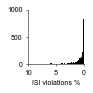

In [43]:
plt.figure(figsize=(2.8*cm, 2.8*cm))
ax = plt.gca()

plt.bar(bins[:-1] + bin_size / 2, isi_hist, width=bin_size, color='black')

plt.xlim(0, 10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.gca().invert_xaxis()  # Reverse X axis direction
ax.set_yticks([0,500,1000])
plt.xlabel('ISI violations %', fontproperties=arial_font,fontsize=7)
plt.xticks(fontproperties=arial_font,fontsize=7)
plt.yticks(fontproperties=arial_font,fontsize=7)

plt.tight_layout(pad=0.05)

plt.savefig(save_path + '/ISI_viols.svg', format='svg', dpi=600)
plt.savefig(save_path + '/ISI_viols.pdf', format='pdf', dpi=600)

plt.show()


In [39]:
AMPs=np.concatenate(ALL_AMPs)
AMPs=AMPs[np.isfinite(AMPs)]
AMPs[AMPs>250]=250
AMPs[AMPs==0]=np.nan
bin_size=5
bins=np.arange(0,np.nanmax(AMPs)+5*bin_size,bin_size)
amp_hist,_=np.histogram(AMPs,bins=bins)

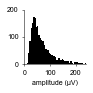

In [40]:
plt.figure(figsize=(2.8*cm,2.8*cm))
ax=plt.gca()
plt.bar(bins[:-1]-bin_size/2,amp_hist,width=bin_size,color='black')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xlabel('amplitude (μV)',fontproperties=arial_font,fontsize=7)
#plt.ylabel('Unit Counts',fontproperties=arial_font)
plt.xticks([0,100,200],[0,100,200],fontproperties=arial_font,fontsize=7)
plt.yticks([0,100,200],[0,100,200],fontproperties=arial_font,fontsize=7)
plt.xlim([0,240])
plt.ylim([0,200])
plt.tight_layout(pad=0.05)

plt.savefig(save_path+'/Amps.svg',format='svg',dpi=600)
plt.savefig(save_path+'/Amps.pdf',format='pdf',dpi=600)

plt.show()

In [ ]:
AP_sRate=30000
check=False
spike_times=[]
for i in ALL_WAVEFORMs:
    for j in i:
        baseline=np.mean(j[0:20])
        amp=np.max(j)-np.min(j)
        if amp>15: #In case a unit loaded incorrectly
            peak=np.argmax(j)
            valley=np.argmin(j)
            spike_time=(peak-valley)/AP_sRate
            spike_times.append(spike_time)
            
            #last check for bad waveforms
            if check==True:
                plt.figure()

                plt.title(spike_time)
                plt.axis('off')

                plt.plot(j,color='black',linewidth=5)
                plt.show()
        else:
            print('noise unit detected')

In [23]:
spike_times=np.asarray(spike_times)*1000

In [32]:
bin_size=0.046
bins=np.arange(0,np.max(spike_times)+bin_size,bin_size)
time_hist,_=np.histogram(spike_times,bins=bins)

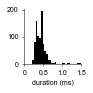

In [34]:
plt.figure(figsize=(2.8*cm,2.8*cm))
ax=plt.gca()
plt.bar(bins[:-1],time_hist,width=bin_size,color='black')
#plt.yticks([])

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xlim([0,1.5])
plt.yticks([0,100,200],[0,100,200],fontproperties=arial_font,fontsize=7)
plt.xticks([0,0.5,1,1.5],[0,0.5,1.0,1.5],fontproperties=arial_font,fontsize=7)
plt.xlabel('duration (ms)',fontproperties=arial_font,fontsize=7)
plt.tight_layout(pad=0.05)

plt.savefig(save_path+'/waveform_duration.svg',format='svg',dpi=600)
plt.savefig(save_path+'/waveform_duration.pdf',format='svg',dpi=600)

plt.show()

In [26]:
Ds=[]
for i in range(len(ALL_G_CHANNELS)):
    if len(ALL_REAL_CHANNELS[i])==len(ALL_G_CHANNELS[i]):
        for j in range(len(ALL_REAL_CHANNELS[i])):
            if hasattr(ALL_REAL_CHANNELS[i][j], '__len__'):
                pass
            else:
                d=ALL_REAL_CHANNELS[i][j]-ALL_G_CHANNELS[i][j]
                Ds.append(d)

In [35]:
bin_size=1
ext=np.nanmax(np.abs(Ds))
bins=np.arange(-ext,+ext+bin_size,bin_size)
Ds_hist,_=np.histogram(Ds,bins=bins)

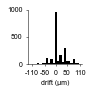

In [37]:
plt.figure(figsize=(2.8*cm,2.8*cm))
ax=plt.gca()
plt.bar(bins[:-1],Ds_hist,width=bin_size,color='black')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xlabel('drift (μm)',fontproperties=arial_font,fontsize=7)
plt.xticks([-11,-5,0,5,11],[-110,-50,0,50,110],fontproperties=arial_font,fontsize=7)
#plt.ylabel('Unit Counts',fontproperties=arial_font)
plt.yticks([0,500,1000],[0,500,1000],fontproperties=arial_font,fontsize=7)
plt.tight_layout(pad=0.05)
plt.savefig(save_path+'/waveform_drift.svg',format='svg',dpi=600)
plt.savefig(save_path+'/waveform_drift.pdf',format='pdf',dpi=600)

plt.show()

In [8]:
FLAT_WAVEFORMS=[]
for i in range(len(ALL_WAVEFORMs)):
    for j in range(len(ALL_WAVEFORMs[i])):
        if len(ALL_WAVEFORMs[i][j])!=91 or ALL_AMPs[i][j]<30:
            continue
        else:
            FLAT_WAVEFORMS.append(ALL_WAVEFORMs[i][j])

In [9]:
FLAT_WAVEFORMS=np.asarray(FLAT_WAVEFORMS)

In [60]:
def center_align_waveforms(waveforms):
    aligned = []
    center = waveforms.shape[1] // 2  # center index of waveform

    for wf in waveforms:
        max_i = np.argmax(wf)
        min_i = np.argmin(wf)
        max_val = wf[max_i]
        min_val = wf[min_i]

        if abs(max_val) > abs(min_val):
            shift = center - max_i  # align max to center
        else:
            shift = center - min_i  # align min to center

        # Shift with edge-padding
        if shift > 0:
            padded = np.pad(wf, (shift, 0), mode='edge')[:len(wf)]
        elif shift < 0:
            padded = np.pad(wf, (0, -shift), mode='edge')[-shift:]
        else:
            padded = wf

        aligned.append(padded)

    return np.array(aligned)
# Classification function
def classify_waveform(wf):
    waveform = wf.copy()
    max_val = np.max(waveform)
    min_val = np.min(waveform)
    threshold = 0.2 * max(abs(max_val), abs(min_val))

    if max_val > abs(min_val):
        return 'positive'

    peaks, _ = find_peaks(waveform, prominence=threshold)
    troughs, _ = find_peaks(-waveform, prominence=threshold)

    extrema = sorted([(i, 'peak') for i in peaks] + [(i, 'trough') for i in troughs], key=lambda x: x[0])
    pattern = [e[1] for e in extrema]

    n_peaks = len(peaks)
    n_troughs = len(troughs)
    n_extrema = len(pattern)

    if n_extrema == 0:
        return 'unclassified'
    elif n_extrema == 1:
        return 'negative monophasic'
    elif n_peaks >= 1 and n_troughs >= 1:
        if n_extrema == 2:
            if pattern[0] == 'peak' and pattern[1] == 'trough':
                return 'negative biphasic peak_before_trough'
            elif pattern[0] == 'trough' and pattern[1] == 'peak':
                return 'negative biphasic peak_after_trough'
            else:
                return 'negative biphasic peak_before_trough'
        elif n_extrema >= 3:
            changes = sum(pattern[i] != pattern[i+1] for i in range(len(pattern)-1))
            if changes >= 2:
                return 'negative triphasic'
            else:
                return 'negative biphasic peak_before_trough'
    return 'unclassified'

In [ ]:
# Align waveforms
aligned_waveforms = center_align_waveforms(FLAT_WAVEFORMS)

# Normalize (z-score)
normalized = (aligned_waveforms - aligned_waveforms.mean(axis=1, keepdims=True)) / aligned_waveforms.std(axis=1, keepdims=True)

# Bad indices
bad_indexes = {1205, 1435, 328, 1759} #manually identified units that don't align correctly, thus forming outliers in PCA



# Classify waveforms
waveform_labels = [classify_waveform(wf) for wf in normalized]

# Filter valid indices
valid_indices = [i for i, lbl in enumerate(waveform_labels) if lbl != 'unclassified' and i not in bad_indexes]
valid_labels = [waveform_labels[i] for i in valid_indices]
valid_waveforms = normalized[valid_indices]

# Color mapping
color_map = {
    'positive': 'orange',
    'negative monophasic': 'blue',
    'negative biphasic peak_before_trough': 'green',
    'negative biphasic peak_after_trough': 'purple',
    'negative triphasic': 'red',
}

In [79]:
pca_2d = PCA(n_components=2).fit_transform(valid_waveforms)
pca_3d = PCA(n_components=3).fit_transform(valid_waveforms)


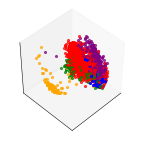

In [151]:
# Define higher alpha for blue group
point_alpha = [0.9 if col == 'blue' else 0.7 for col in colors]

fig = plt.figure(figsize=(5/2.54, 5/2.54))
ax = fig.add_subplot(111, projection='3d')

# Use a loop to plot each point with its own alpha
for i in range(len(pca_3d)):
    ax.scatter(pca_3d[i, 0], pca_3d[i, 1], pca_3d[i, 2],
               c=colors[i], s=4.5, alpha=point_alpha[i])

#ax.set_xlabel('PCA 1', fontproperties=arial_font)
#ax.set_ylabel('PCA 2', fontproperties=arial_font)
#ax.set_zlabel('PCA 3', fontproperties=arial_font)
ax.view_init(elev=45, azim=45)

# Remove ticks and tick labels on all axes
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis.set_ticks([])
    axis.set_ticklabels([])

plt.tight_layout()
plt.savefig(save_path + 'PCA_waveforms.svg', format='svg', dpi=600)
plt.savefig(save_path + 'PCA_waveforms.pdf', format='pdf', dpi=600)
plt.show()



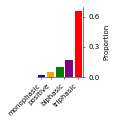

In [206]:
from collections import Counter
import matplotlib.font_manager as fm


# Flatten labels if needed
flat_labels = [lbl[0] if isinstance(lbl, list) else lbl for lbl in valid_labels]

# Count and compute proportions
label_counts = Counter(flat_labels)
total = sum(label_counts.values())
proportions = {label: count / total for label, count in label_counts.items()}

# Sort categories by proportion descending (tallest first)
sorted_items = sorted(proportions.items(), key=lambda x: x[1], reverse=True)
labels, values = zip(*sorted_items)

# Reverse order so tallest is on the right
labels = labels[::-1]
values = values[::-1]

# Get colors in reversed order to match
bar_colors = [color_map.get(label, 'gray') for label in labels]

# Set font
arial_font = fm.FontProperties(family='Arial')

# Plot
fig, ax = plt.subplots(figsize=(4/2.54, 4.4/2.54))

bars = ax.bar(range(len(labels)), values, color=bar_colors)

# Do NOT invert x-axis (so tallest bar on right)

# Move y-axis to the right
ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")

# Remove y-axis ticks and labels (you said you want no text)
ax.set_yticks([0,0.3,0.6])

# Remove x-axis ticks and labels first
ax.set_xticks([])
ax.set_xticklabels([])

# Hide top and left spines
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)

# Optional y-axis label placeholder (empty)
ax.set_ylabel('Proportion')

# Custom x-axis ticks and labels matching bar positions, including biphasic between bars 2 and 3
tick_positions = [0, 1, 2.5, 4]
tick_labels = ['monophasic', 'positive', 'biphasic', 'triphasic']

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontproperties=arial_font, rotation=45, ha='right')

# Set x-limits to fit labels nicely
ax.set_xlim(-0.5, len(labels) - 0.5)

plt.tight_layout()
plt.savefig(save_path + 'waveform_category_proportions_vertical_swapped.pdf', format='pdf', dpi=600)
plt.savefig(save_path + 'waveform_category_proportions_vertical_swapped.svg', format='svg', dpi=600)
plt.show()





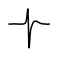

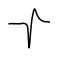

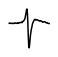

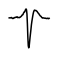

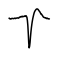

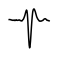

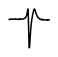

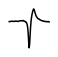

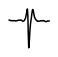

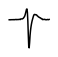

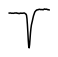

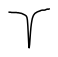

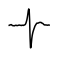

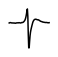

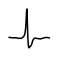

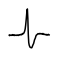

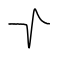

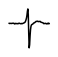

In [147]:
cm=1/2.54
for i in indexes:
    plt.figure(figsize=(2*cm,2*cm))
    plt.plot(FLAT_WAVEFORMS[i],color='black',linewidth=1.5)
    plt.axis('off')
    plt.savefig(save_path+'/example_waveform{}.pdf'.format(i),format='pdf',dpi=600)
    plt.show()